In [ ]:
!pip install -q kaggle

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [ ]:
import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)
shutil.move("kaggle.json", "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle credentials configured!")

Kaggle credentials configured!


In [ ]:
!kaggle datasets download \
    -d tawsifurrahman/covid19-radiography-database \
    -p /content

Dataset URL: https://www.kaggle.com/datasets/tawsifurrahman/covid19-radiography-database
License(s): copyright-authors
100% 778M/778M [00:06<00:00, 125MB/s]



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import InceptionResNetV2
from tensorflow.keras.layers import Dense, Flatten, Input, Dropout

In [ ]:
!unzip -q /content/covid19-radiography-database.zip -d /content/covid_dataset

In [ ]:
import os

for root, dirs, files in os.walk("/content/covid_dataset"):
    images = [
        f for f in files
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]
    if images:
        print(root, ":", len(images), "images")

/content/covid_dataset/COVID-19_Radiography_Dataset/COVID/masks : 3616 images
/content/covid_dataset/COVID-19_Radiography_Dataset/COVID/images : 3616 images
/content/covid_dataset/COVID-19_Radiography_Dataset/Viral Pneumonia/masks : 1345 images
/content/covid_dataset/COVID-19_Radiography_Dataset/Viral Pneumonia/images : 1345 images
/content/covid_dataset/COVID-19_Radiography_Dataset/Lung_Opacity/masks : 6012 images
/content/covid_dataset/COVID-19_Radiography_Dataset/Lung_Opacity/images : 6012 images
/content/covid_dataset/COVID-19_Radiography_Dataset/Normal/masks : 10192 images
/content/covid_dataset/COVID-19_Radiography_Dataset/Normal/images : 10192 images


In [ ]:

import tensorflow as tf

DATASET_DIR = (
    "/content/covid_dataset/"
    "COVID-19_Radiography_Dataset"
)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names
print("Classes:", class_names)


Found 42330 files belonging to 4 classes.
Using 33864 files for training.
Found 42330 files belonging to 4 classes.
Using 8466 files for validation.
Classes: ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']


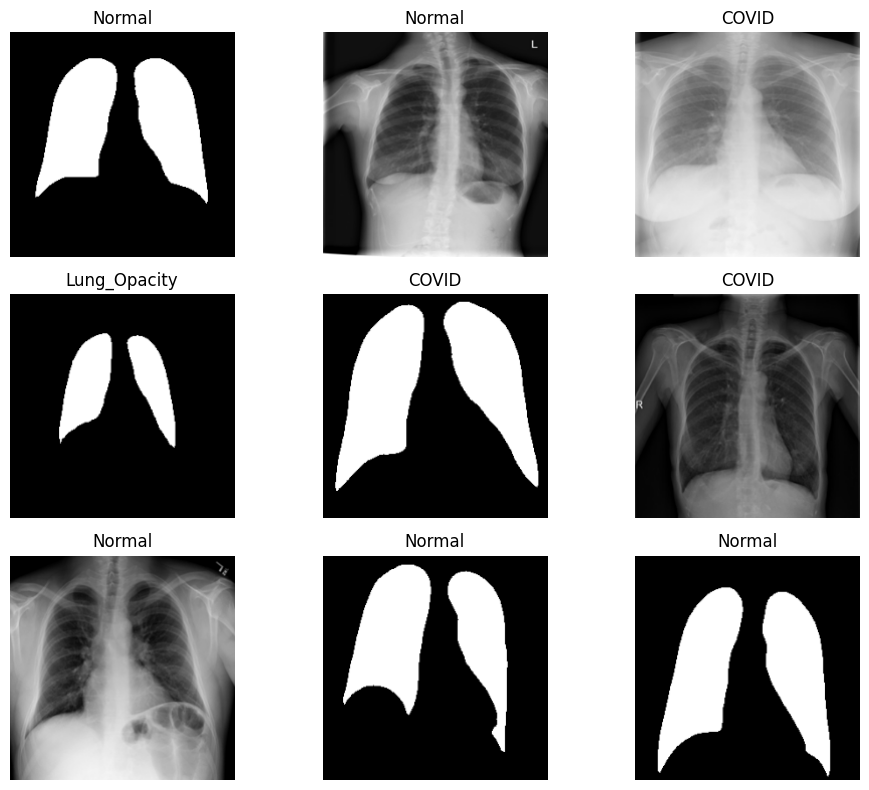

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import tensorflow as tf
import os

BASE_DIR = "/content/covid_dataset/COVID-19_Radiography_Dataset"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    BASE_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=["COVID", "Lung_Opacity", "Normal", "Viral Pneumonia"],
    )


Found 42330 files belonging to 4 classes.
Using 33864 files for training.


In [ ]:

import os
import shutil

BASE_DIR = "/content/covid_dataset/COVID-19_Radiography_Dataset"
CLEAN_DIR = "/content/covid_images"

classes = ["COVID", "Lung_Opacity", "Normal", "Viral Pneumonia"]

os.makedirs(CLEAN_DIR, exist_ok=True)

for cls in classes:
    source = os.path.join(BASE_DIR, cls, "images")
    target = os.path.join(CLEAN_DIR, cls)
    os.makedirs(target, exist_ok=True)

    for filename in os.listdir(source):
        if filename.lower().endswith((".png", ".jpg", ".jpeg")):
            src = os.path.join(source, filename)
            dst = os.path.join(target, filename)

            if not os.path.exists(dst):
                os.symlink(src, dst)

    print(cls, ":", len(os.listdir(target)), "X-ray images")


COVID : 3616 X-ray images
Lung_Opacity : 6012 X-ray images
Normal : 10192 X-ray images
Viral Pneumonia : 1345 X-ray images


In [ ]:

import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/covid_images",
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/covid_images",
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)


Found 21165 files belonging to 4 classes.
Using 16932 files for training.
Found 21165 files belonging to 4 classes.
Using 4233 files for validation.
Classes: ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']
Number of classes: 4


In [ ]:

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Rescaling(1./127.5, offset=-1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

# Improve data-loading performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

# Stop training automatically if validation loss stops improving
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[early_stopping]
)


Epoch 1/5
530/530 ━━━━━━━━━━━━━━━━━━━━ 60s 90ms/step - accuracy: 0.7811 - loss: 0.5710 - val_accuracy: 0.8531 - val_loss: 0.3954
Epoch 2/5
530/530 ━━━━━━━━━━━━━━━━━━━━ 37s 71ms/step - accuracy: 0.8409 - loss: 0.4247 - val_accuracy: 0.8710 - val_loss: 0.3516
Epoch 3/5
530/530 ━━━━━━━━━━━━━━━━━━━━ 40s 69ms/step - accuracy: 0.8564 - loss: 0.3930 - val_accuracy: 0.8677 - val_loss: 0.3472
Epoch 4/5
530/530 ━━━━━━━━━━━━━━━━━━━━ 44s 75ms/step - accuracy: 0.8609 - loss: 0.3788 - val_accuracy: 0.8781 - val_loss: 0.3356
Epoch 5/5
530/530 ━━━━━━━━━━━━━━━━━━━━ 41s 74ms/step - accuracy: 0.8636 - loss: 0.3653 - val_accuracy: 0.8748 - val_loss: 0.3391


In [ ]:
print("history exists:", "history" in globals())
print("model exists:", "model" in globals())

history exists: True
model exists: True


Best validation accuracy: 0.8781006336212158


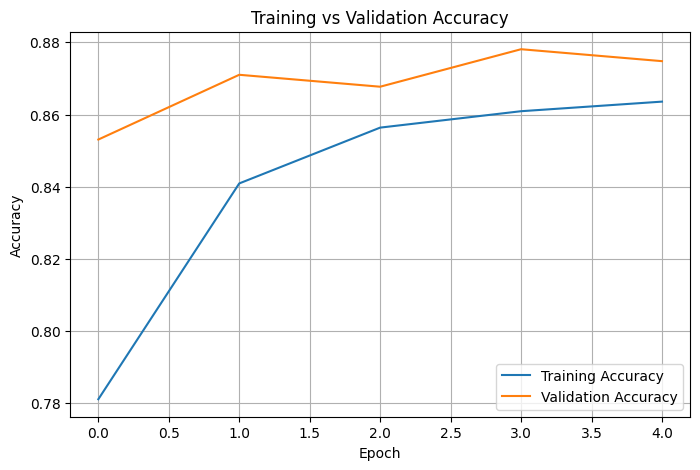

In [ ]:
import matplotlib.pyplot as plt

print("Best validation accuracy:",
      max(history.history["val_accuracy"]))

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(predictions, axis=1))
    y_true.extend(labels.numpy())

print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))


                 precision    recall  f1-score   support

          COVID       0.87      0.81      0.84       713
   Lung_Opacity       0.88      0.83      0.86      1165
         Normal       0.88      0.92      0.90      2058
Viral Pneumonia       0.90      0.94      0.92       297

       accuracy                           0.88      4233
      macro avg       0.88      0.87      0.88      4233
   weighted avg       0.88      0.88      0.88      4233



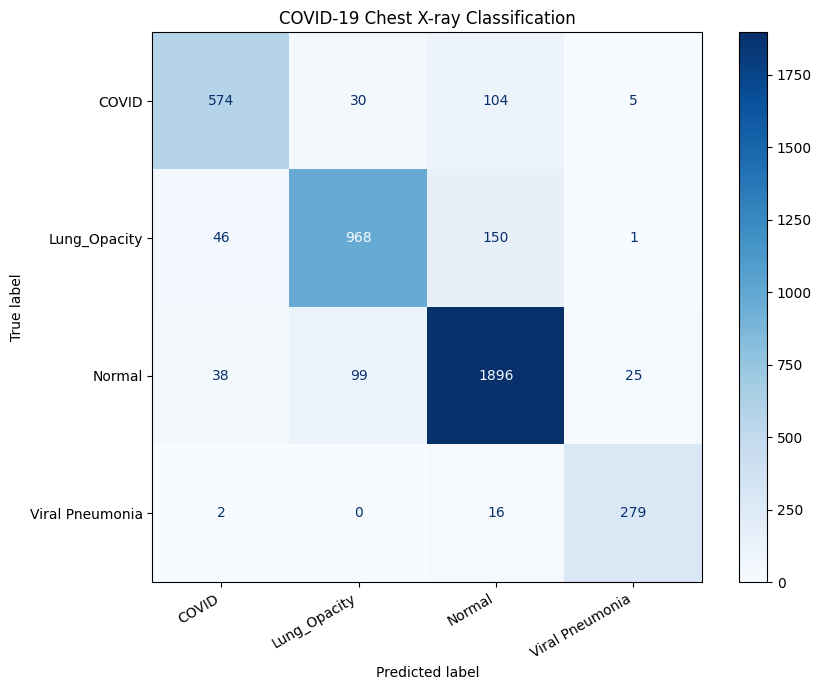

In [ ]:

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.xticks(rotation=30, ha="right")
plt.title("COVID-19 Chest X-ray Classification")
plt.tight_layout()
plt.show()


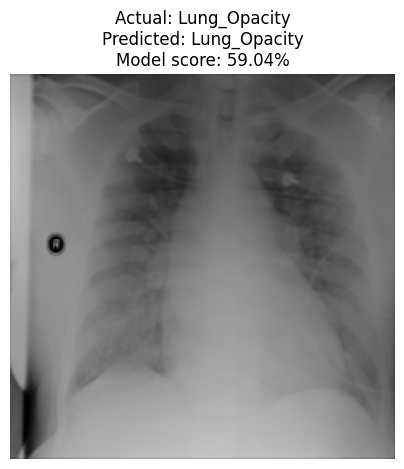

Actual class: Lung_Opacity
Predicted class: Lung_Opacity
Model score: 59.04%


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Select one image from the validation dataset
for images, labels in val_ds.take(1):
    sample_image = images[0]
    actual_label = int(labels[0].numpy())
    break

# Predict the class
prediction = model.predict(
    tf.expand_dims(sample_image, axis=0),
    verbose=0
)

predicted_label = int(np.argmax(prediction[0]))
confidence = float(np.max(prediction[0])) * 100

# Display the image and result
plt.figure(figsize=(5, 5))
plt.imshow(sample_image.numpy().astype("uint8"))
plt.axis("off")
plt.title(
    f"Actual: {class_names[actual_label]}\n"
    f"Predicted: {class_names[predicted_label]}\n"
    f"Model score: {confidence:.2f}%"
)
plt.show()

print("Actual class:", class_names[actual_label])
print("Predicted class:", class_names[predicted_label])
print(f"Model score: {confidence:.2f}%")


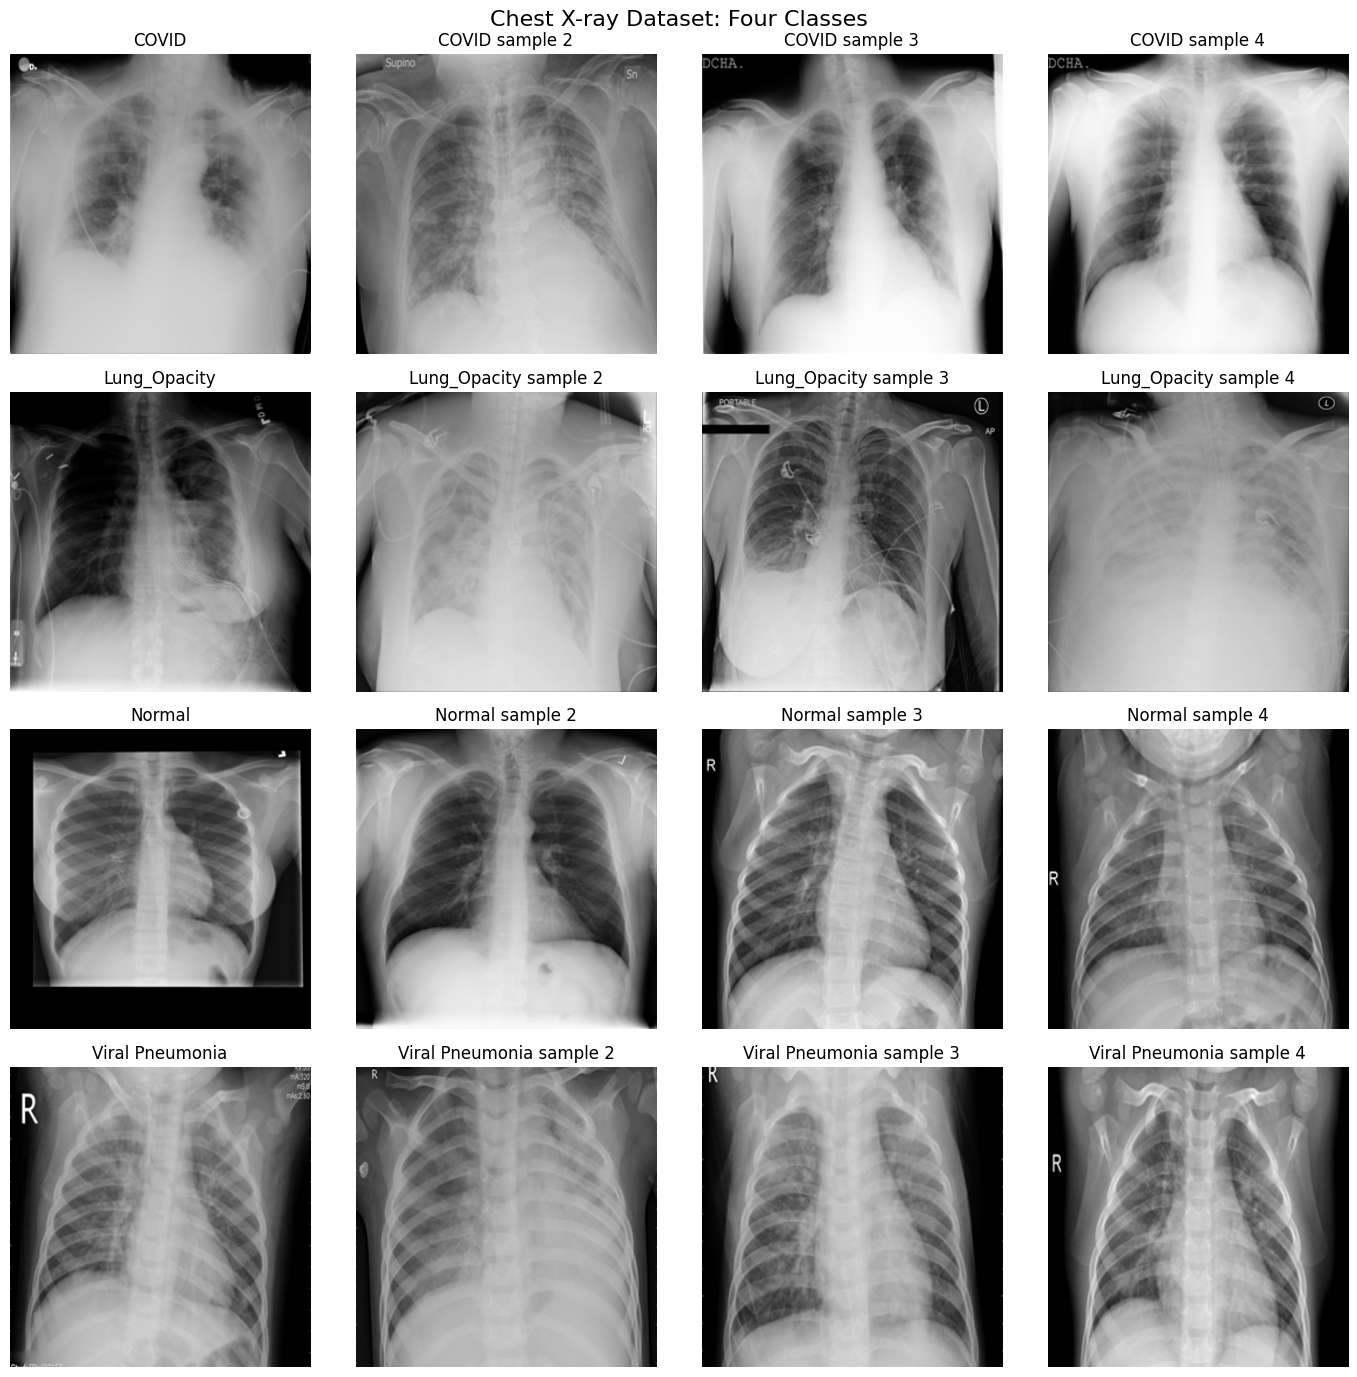

In [ ]:

import os
import matplotlib.pyplot as plt
from PIL import Image

BASE_DIR = "/content/covid_dataset/COVID-19_Radiography_Dataset"
classes = ["COVID", "Lung_Opacity", "Normal", "Viral Pneumonia"]

fig, axes = plt.subplots(4, 4, figsize=(14, 14))

for row, cls in enumerate(classes):
    image_dir = os.path.join(BASE_DIR, cls, "images")
    image_files = sorted([
        f for f in os.listdir(image_dir)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ])

    for col in range(4):
        img_path = os.path.join(image_dir, image_files[col])
        img = Image.open(img_path).convert("RGB")

        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].set_title(cls if col == 0 else f"{cls} sample {col+1}")
        axes[row, col].axis("off")

plt.suptitle("Chest X-ray Dataset: Four Classes", fontsize=16)
plt.tight_layout()
plt.show()


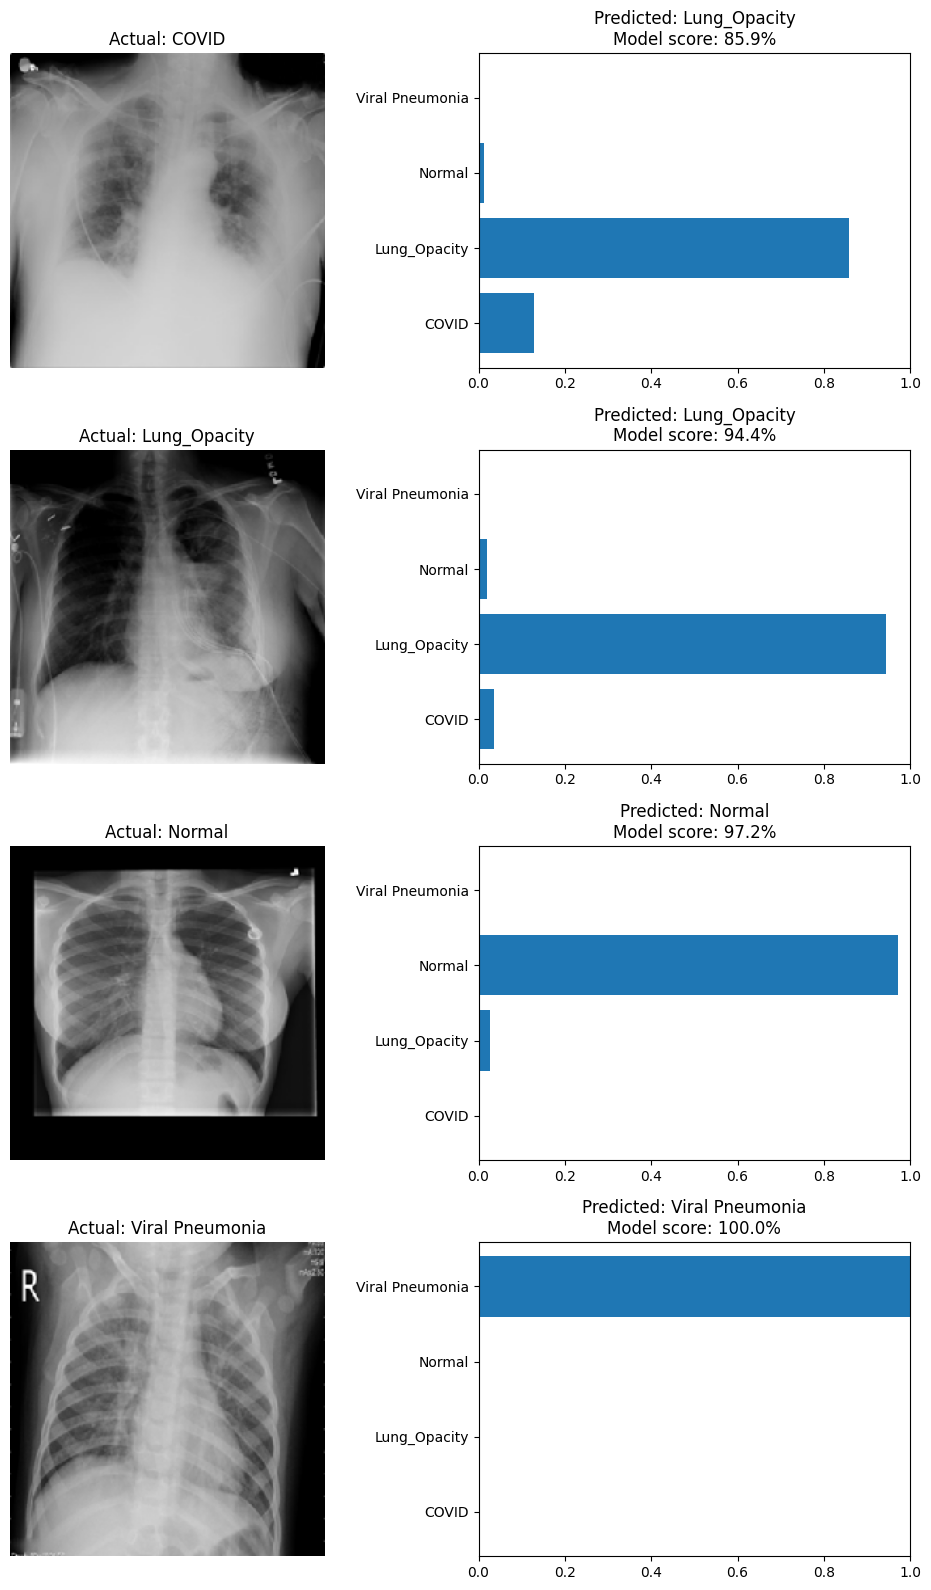

In [ ]:

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

BASE_DIR = "/content/covid_dataset/COVID-19_Radiography_Dataset"

fig, axes = plt.subplots(4, 2, figsize=(10, 16))

for row, cls in enumerate(class_names):
    image_dir = os.path.join(BASE_DIR, cls, "images")
    image_files = sorted([
        f for f in os.listdir(image_dir)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ])

    img_path = os.path.join(image_dir, image_files[0])

    img = tf.keras.utils.load_img(
        img_path, target_size=(224, 224)
    )
    img_array = tf.keras.utils.img_to_array(img)

    probs = model.predict(
        tf.expand_dims(img_array, axis=0),
        verbose=0
    )[0]

    pred_idx = int(np.argmax(probs))
    score = float(probs[pred_idx]) * 100

    axes[row, 0].imshow(img)
    axes[row, 0].set_title(f"Actual: {cls}")
    axes[row, 0].axis("off")

    axes[row, 1].barh(class_names, probs)
    axes[row, 1].set_xlim(0, 1)
    axes[row, 1].set_title(
        f"Predicted: {class_names[pred_idx]}\n"
        f"Model score: {score:.1f}%"
    )

plt.tight_layout()
plt.show()


In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os

save_path = "/content/drive/MyDrive/IPCV_COVID19_Project"
os.makedirs(save_path, exist_ok=True)

model_path = os.path.join(save_path, "covid19_model.keras")

model.save(model_path)

print("Model saved successfully!")
print("File exists:", os.path.exists(model_path))
print("Saved at:", model_path)


Model saved successfully!
File exists: True
Saved at: /content/drive/MyDrive/IPCV_COVID19_Project/covid19_model.keras
